# Семинар 3. Обнаружение радиолокационных сигналов на спектрограммах (RadDet)

На лекции мы обсудили задачу: на спектрограмме широкой полосы эфира найти радиолокационные сигналы — когда, на какой частоте и какого типа. Сегодня решим её двумя способами и честно сравним:

1. **Классический энергетический обнаружитель** — порог над уровнем шума, без обучения.
2. **YOLO26**, обученный на RadDet с аугментациями, подходящими для спектрограмм.

Сравнивать будем по каждому уровню ОСШ отдельно: на +20 дБ и на −20 дБ это совсем разные задачи.

**Данные:** RadDet-9T (до 9 сигналов в кадре), одни и те же кадры в двух разрешениях: 128×128 и 512×512.  
[Скачать датасет](https://www.kaggle.com/datasets/abcxyzi/raddet-icassp-2025/data?select=RadDet40k512HW009Tv2.tar.part-aa)

## 0. Подготовка

In [ ]:
!pip install -q ultralytics

In [2]:
import os, glob, json, zipfile, urllib.request, time
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
from scipy import ndimage as ndi

WEIGHTS_128 = r"D:\data\RADAR_DATASETS\RadDet\runs\raddet\yolo26s_img128\weights\best.pt"   # веса, обученные заранее на GPU
WEIGHTS_512 = r"D:\data\RADAR_DATASETS\RadDet\runs\raddet\yolo26s_img512\weights\best.pt"
ROOT = r"D:\data\RADAR_DATASETS\RadDet\RadDet40k128HW009Tv2"
ROOT_512 = r"D:\data\RADAR_DATASETS\RadDet\RadDet40k512HW009Tv2"

for root in [ROOT, ROOT_512]:
    print(root, {sp: len(glob.glob(f"{root}/images/{sp}/*.png")) for sp in ['train', 'val', 'test']})

D:\data\RADAR_DATASETS\RadDet\RadDet40k128HW009Tv2 {'train': 14001, 'val': 6001, 'test': 20001}
D:\data\RADAR_DATASETS\RadDet\RadDet40k512HW009Tv2 {'train': 14001, 'val': 6001, 'test': 20001}


## 1. Что лежит в датасете

Для каждого кадра — три файла с одинаковым номером:
- `images/.../000000000000.png` — спектрограмма 128×128;
- `labels/.../000000000000.txt` — рамки в формате YOLO: `класс x_центра y_центра ширина высота` (доли от размера картинки). **Ось X — время, ось Y — частота.** Если в кадре только шум, файла нет;
- `metadata/.../000000000000.json` — параметры каждого сигнала: класс, центральная частота, полоса, длительность импульса, число импульсов и **ОСШ** кадра.

In [3]:
def load_labels(path, W=128, H=128):
    """YOLO-разметка -> массив (N,5): class, x1, y1, x2, y2 в пикселях."""
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        return np.zeros((0, 5))
    l = np.loadtxt(path, ndmin=2)
    c, xc, yc, w, h = l.T
    return np.c_[c, (xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H]

CLASSES = ['Rect', 'Barker', 'Frank', 'P1', 'P2', 'P3', 'P4', 'Px', 'ZadoffChu', 'LFM', 'FMCW']

def frame_ids(split):
    return sorted(os.path.basename(f)[:-4] for f in glob.glob(f"{ROOT}/images/{split}/*.png"))

def load_frame(split, i, root=ROOT):
    img = np.array(Image.open(f"{root}/images/{split}/{i}.png"))[..., :3]
    S = img.shape[0]
    lab = load_labels(f"{root}/labels/{split}/{i}.txt", S, S)
    meta = json.load(open(f"{root}/metadata/{split}/{i}.json"))
    return img, lab, meta

i0 = frame_ids('test')[0]
img, lab, meta = load_frame('test', i0)
print(open(f"{ROOT}/labels/test/{i0}.txt").read())
print(json.dumps(meta[0], indent=1))

0 0.611153 0.540000 0.250000 0.039563
9 0.263525 0.460000 0.040000 0.116000
4 0.273151 0.780000 0.550000 0.041063
3 0.804995 0.620000 0.055000 0.041920
3 0.259591 0.660000 0.035000 0.041920

{
 "ClassIdx": 0,
 "RadarStatus": 1,
 "SamplingFrequency": 500000000,
 "Bandwidth": 249999.99999999997,
 "RadarSignalCenterFreq": -20000000,
 "RadarSignalStartTime": 0.001072306,
 "RadarSignalEndTime": 0.001472306,
 "PulseWidth": 4.000000000000001e-06,
 "PulsesPerSecond": 10000.0,
 "NumberOfPulses": 4.0,
 "PhaseOffset": -0.5585053606381855,
 "SequenceLength": 1000000,
 "SNR": 12.0
}


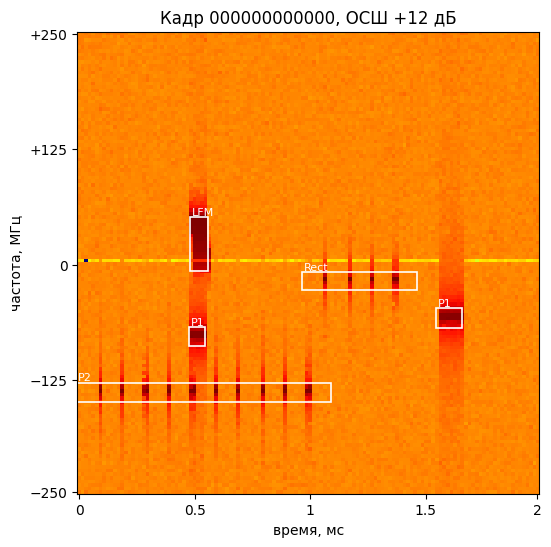

In [4]:
def show(img, lab=None, ax=None, title=None, color='white', pred=None):
    ax = ax or plt.subplots(figsize=(6, 6))[1]
    ax.imshow(img, cmap='jet' if img.ndim == 2 else None)
    if lab is not None:
        for c, x1, y1, x2, y2 in lab:
            ax.add_patch(patches.Rectangle((x1 - .5, y1 - .5),
                                           x2 - x1, y2 - y1, 
                                           fill=False, 
                                           ec=color, 
                                           lw=1.2))
            ax.text(x1, y1 - 1, CLASSES[int(c)], color=color, fontsize=8)
    if pred is not None:
        for x1, y1, x2, y2, *_ in pred:
            ax.add_patch(patches.Rectangle((x1 - .5, y1 - .5), 
                                           x2 - x1, y2 - y1, 
                                           fill=False, 
                                           ec='green', 
                                           lw=1.2))
    S = img.shape[0]; t = [0, S // 4, S // 2, 3 * S // 4, S - 1]
    ax.set_xticks(t)
    ax.set_xticklabels(['0', '0.5', '1', '1.5', '2'])
    ax.set_yticks(t)
    ax.set_yticklabels(['+250', '+125', '0', '−125', '−250'])
    ax.set_xlabel('время, мс')
    ax.set_ylabel('частота, МГц')
    ax.set_title(title or '')
    return ax

show(img, lab, title=f"Кадр {i0}, ОСШ {meta[0]['SNR']:+.0f} дБ");

### 1.1. Статистика тестовой выборки

Кадров: 20001, из них только шум: 10%, сигналов в среднем на кадр: 4.5
Медианная высота рамки: 5.4 px из 128 — объекты крошечные


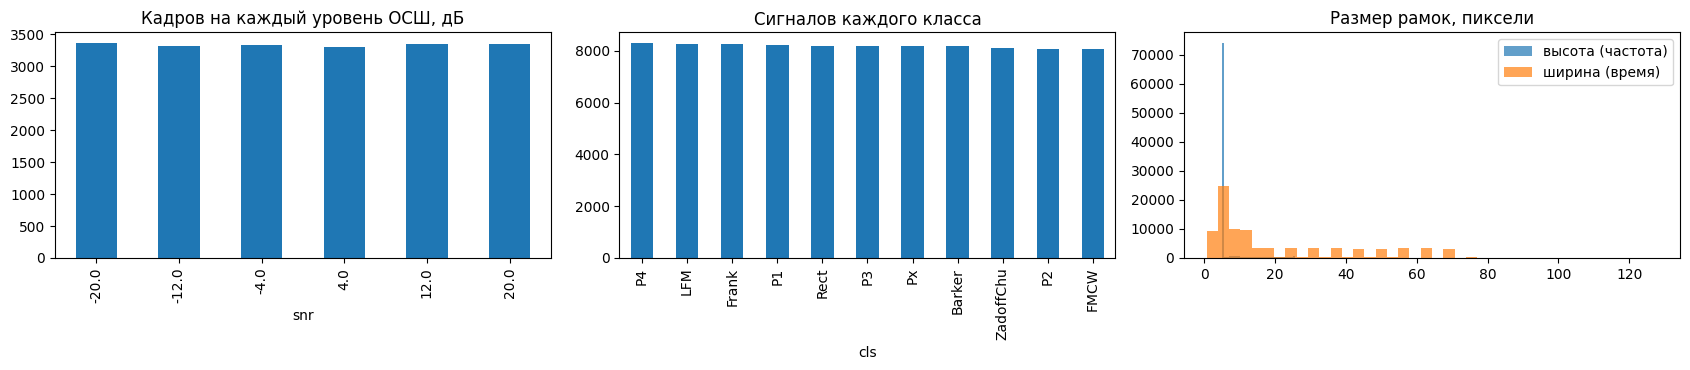

In [14]:
rows = []
for i in frame_ids('test'):
    meta = json.load(open(f"{ROOT}/metadata/test/{i}.json"))
    lab = load_labels(f"{ROOT}/labels/test/{i}.txt")
    rows.append(dict(id=i, snr=meta[0]['SNR'], n=len(lab)))
    for c, x1, y1, x2, y2 in lab:
        rows[-1].setdefault('boxes', []).append((int(c), x2 - x1, y2 - y1))
frames = pd.DataFrame(rows)
boxes = pd.DataFrame([(r.snr, *b) for r in frames.itertuples() for b in (r.boxes if isinstance(r.boxes, list) else [])],
                     columns=['snr', 'cls', 'w', 'h'])
print(f"Кадров: {len(frames)}, из них только шум: {(frames.n == 0).mean():.0%}, сигналов в среднем на кадр: {frames.n.mean():.1f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
frames.snr.value_counts().sort_index().plot.bar(ax=ax[0], title='Кадров на каждый уровень ОСШ, дБ')
boxes.cls.map(lambda c: CLASSES[c]).value_counts().plot.bar(ax=ax[1], title='Сигналов каждого класса')
ax[2].hist(boxes.h, bins=40, alpha=.7, label='высота (частота)'); ax[2].hist(boxes.w, bins=40, alpha=.7, label='ширина (время)')
ax[2].set_title('Размер рамок, пиксели'); ax[2].legend(); plt.tight_layout()
print(f"Медианная высота рамки: {boxes.h.median():.1f} px из 128 — объекты крошечные")

**Что важно:** большинство рамок по высоте около 5 пикселей. Для YOLO это очень мелкие объекты: на самой грубой карте признаков (шаг 32 пикселя) такой сигнал меньше одной клетки.

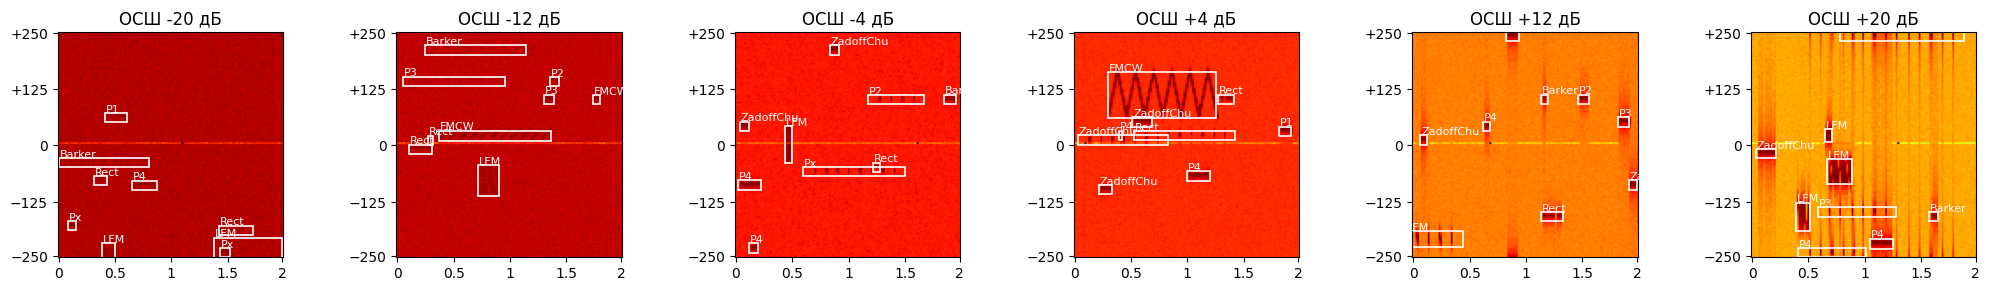

In [15]:
fig, axs = plt.subplots(1, 6, figsize=(20, 3.8))
for ax, s in zip(axs, sorted(frames.snr.unique())):
    i = frames[(frames.snr == s) & (frames.n > 0)].sort_values('n').id.iloc[-1]
    img, lab, _ = load_frame('test', i)
    show(img, lab, ax=ax, title=f"ОСШ {s:+.0f} дБ"); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout()

## 2. Из цвета обратно в мощность

PNG в датасете — это **псевдоцвет**: мощность закодирована палитрой `jet` (синий — мало, тёмно-красный — много). Для классического обнаружителя нужна именно мощность, поэтому вернём её: для каждого пикселя найдём ближайший цвет в палитре jet.

In [7]:
LUT = matplotlib.colormaps['jet'](np.linspace(0, 1, 256))[:, :3] * 255

def to_power(img_rgb):
    """Псевдоцвет (jet) -> относительная мощность 0..1.
    Различных цветов в кадре всего ~100, поэтому ищем ближайший цвет палитры только для них."""
    a = np.asarray(img_rgb)[..., :3].astype(np.int32)
    codes = (a[..., 0] << 16) | (a[..., 1] << 8) | a[..., 2]
    uniq, inv = np.unique(codes, return_inverse=True)
    rgb = np.stack([(uniq >> 16) & 255, (uniq >> 8) & 255, uniq & 255], 1).astype(np.float32)
    idx = ((rgb[:, None, :] - LUT[None]) ** 2).sum(-1).argmin(1)
    return (idx[inv].reshape(codes.shape) / 255.0).astype(np.float32)

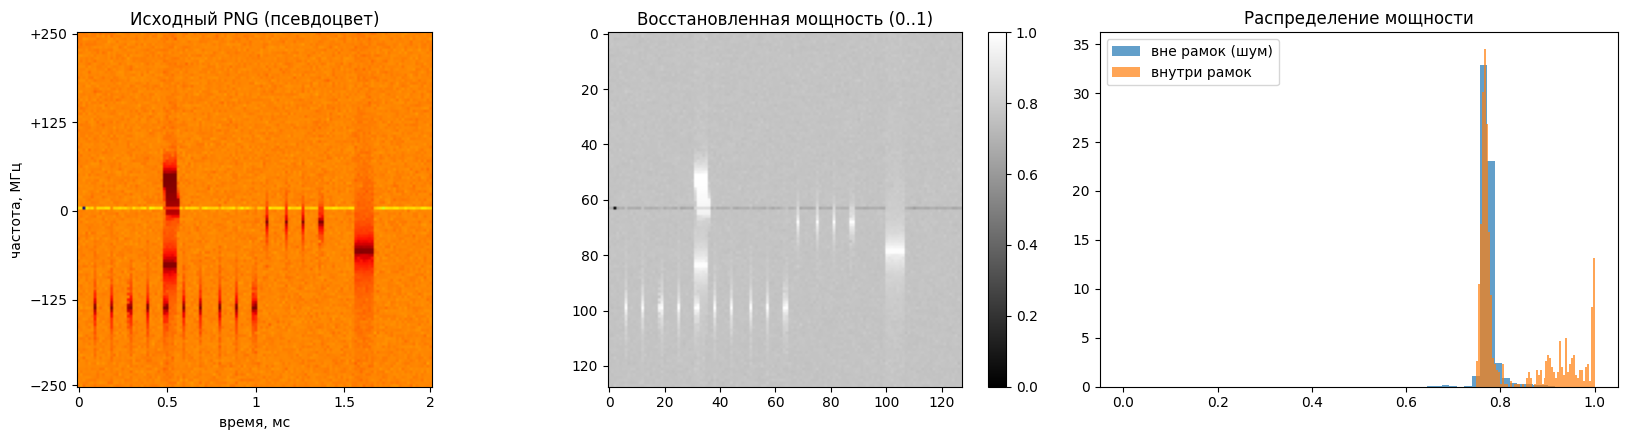

In [8]:
img, lab, meta = load_frame('test', i0)
P = to_power(img)
inside = np.zeros_like(P, bool)
for c, x1, y1, x2, y2 in lab:
    inside[int(y1):int(np.ceil(y2)), int(x1):int(np.ceil(x2))] = True
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
show(img, ax=ax[0], title='Исходный PNG (псевдоцвет)')
im = ax[1].imshow(P, cmap='gray'); ax[1].set_title('Восстановленная мощность (0..1)'); plt.colorbar(im, ax=ax[1])
ax[2].hist(P[~inside], bins=60, alpha=.7, density=True, label='вне рамок (шум)')
ax[2].hist(P[inside], bins=60, alpha=.7, density=True, label='внутри рамок')
ax[2].set_title('Распределение мощности'); ax[2].legend(); plt.tight_layout()

**Наблюдения:**
- шум занимает узкий диапазон значений (≈0.75–0.8), сигналы — до 1;
- внутри рамок тоже много «шумовых» пикселей: рамка охватывает всю пачку импульсов вместе с паузами;
- раскраска нормируется на каждый кадр отдельно, поэтому абсолютный уровень фона у кадров разный — порог надо считать **для каждого кадра**.

## 3. Классический энергетический обнаружитель

Алгоритм (без какого-либо обучения):
1. Уровень шума в каждой строке частоты — **медиана** по времени, разброс — **MAD** (медианное абсолютное отклонение). Обе оценки устойчивы к сигналам, которые занимают малую часть строки.
2. Пиксель считаем «сигнальным», если он выше шума на `k` разбросов. Это тот же принцип, что у CFAR.
3. Импульсы одной пачки склеиваем по времени (морфологическое замыкание), находим связные области.
4. Уточняем полосу по частоте: у сильных коротких импульсов спектр «размазан» боковыми лепестками, поэтому оставляем только строки около пика.

In [9]:
def energy_detector(P, k=4.0, close_t=9, close_f=1, min_area=6, refine=0.5):
    """Классический энергетический обнаружитель на спектрограмме.
    1) уровень шума в каждой строке частоты — медиана по времени, разброс — MAD;
    2) порог: P > шум + k * разброс;
    3) склейка импульсов одной пачки по времени (морфологическое замыкание);
    4) связные области -> рамки. Score = максимальное превышение над шумом (нормированное).
    Все размеры (close_t, close_f, min_area) — в ПИКСЕЛЯХ и подобраны для 128×128."""
    med = np.median(P, axis=1, keepdims=True)
    mad = np.median(np.abs(P - med), axis=1, keepdims=True) * 1.4826 + 1e-3
    z = (P - med) / mad
    mask = z > k
    mask = ndi.binary_closing(mask, structure=np.ones((2 * close_f + 1, close_t)))
    lab, n = ndi.label(mask)
    boxes = []
    for i, sl in enumerate(ndi.find_objects(lab), 1):
        if sl is None: continue
        region = lab[sl] == i
        if region.sum() < min_area: continue
        y1, y2 = sl[0].start, sl[0].stop; x1, x2 = sl[1].start, sl[1].stop
        if refine:
            prof = z[y1:y2, x1:x2].max(axis=1)
            p = int(np.argmax(prof)); lvl = refine * prof[p]
            a = p
            while a > 0 and prof[a - 1] >= lvl: a -= 1
            b = p
            while b < len(prof) - 1 and prof[b + 1] >= lvl: b += 1
            y1, y2 = y1 + a, y1 + b + 1
        score = float(np.clip(z[y1:y2, x1:x2].max() / (10 * k), 0, 1))
        boxes.append((x1, y1, x2, y2, score))
    return np.array(boxes).reshape(-1, 5)


def energy_params(S):
    """Параметры обнаружителя для разрешения S×S.
    На 512×512 пиксель в 4 раза мельче по каждой оси, поэтому склейку по времени и минимальную
    площадь надо пересчитать — иначе пачка импульсов рассыпается на много мелких рамок."""
    if S == 128:
        return dict(close_t=9, close_f=1, min_area=6)
    f = S // 128
    return dict(close_t=9 * f, close_f=2, min_area=6 * f * f // 2)


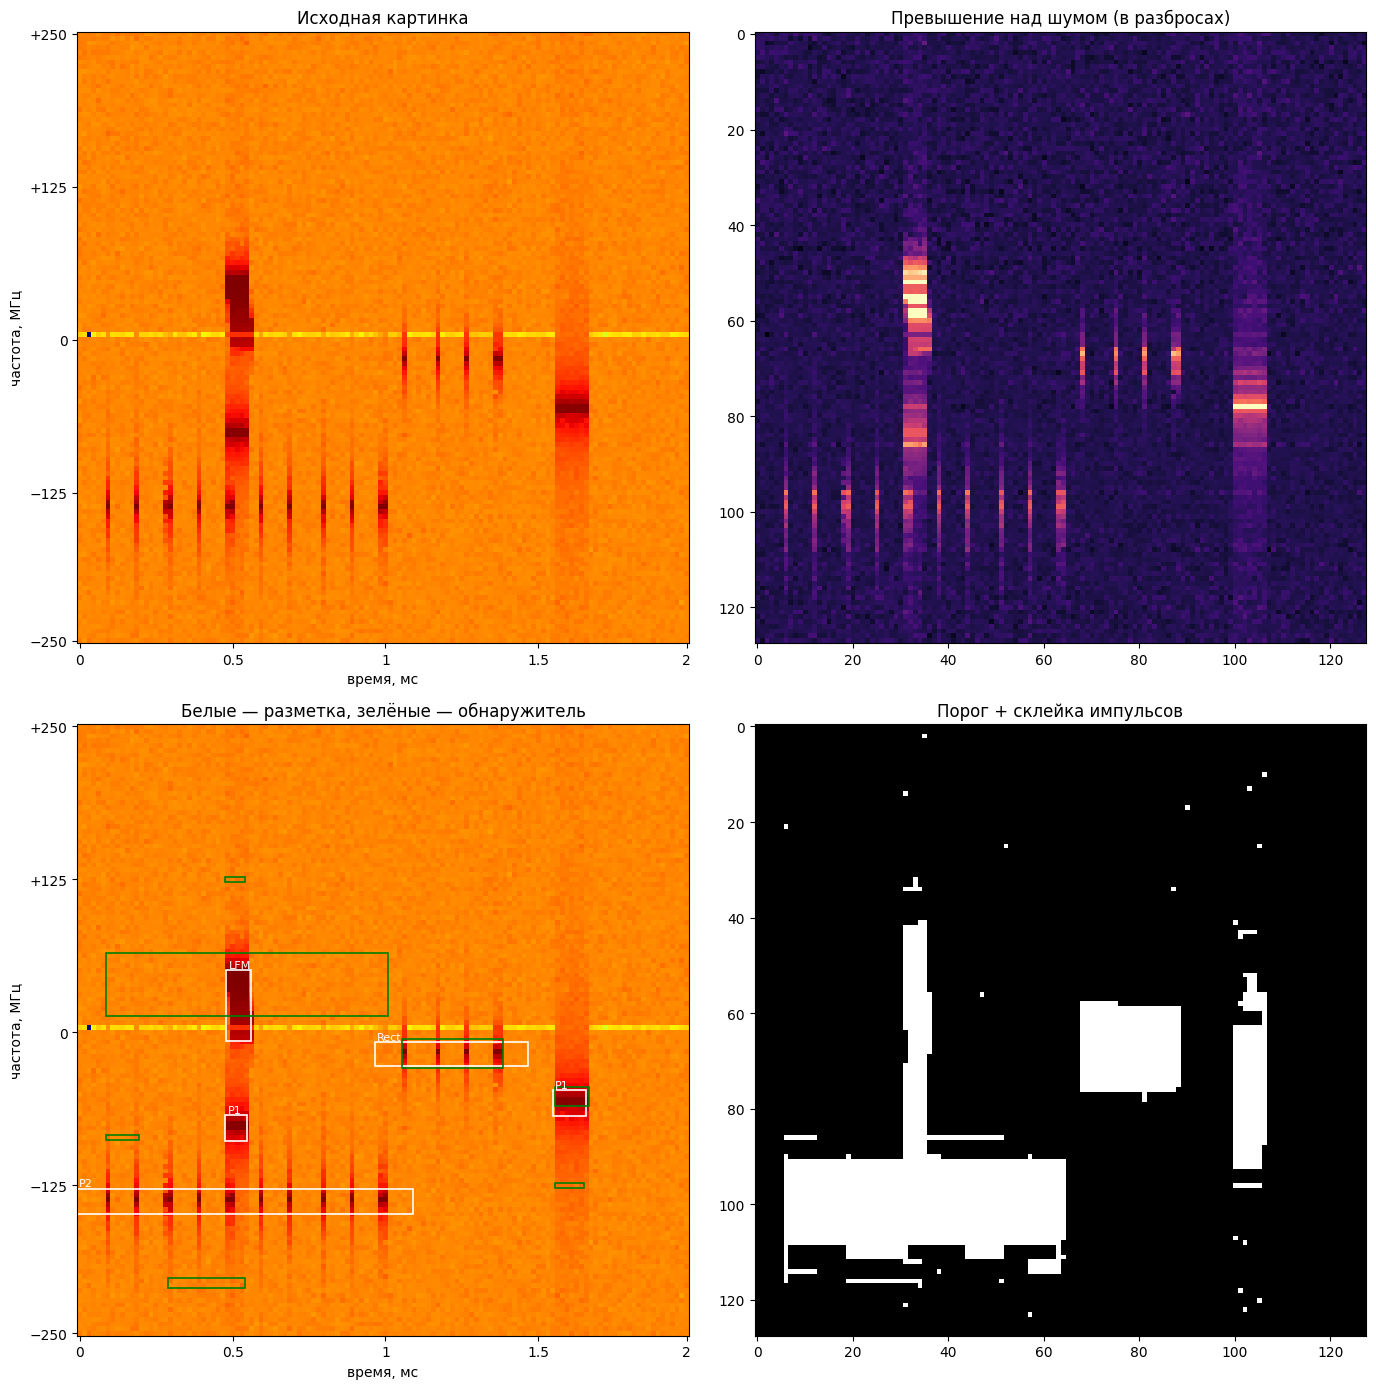

In [10]:
p = to_power(img)
med = np.median(p, axis=1, keepdims=True); mad = np.median(np.abs(p - med), axis=1, keepdims=True) * 1.4826 + 1e-3
z = (p - med) / mad
mask = ndi.binary_closing(z > 4, structure=np.ones((3, 9)))
D = energy_detector(p)
fig, ax = plt.subplots(2, 2, figsize=(14, 14))
show(img, ax = ax[0][0], title = 'Исходная картинка')
ax[0][1].imshow(np.clip(z, -5, 30), cmap='magma'); ax[0][1].set_title('Превышение над шумом (в разбросах)')
ax[1][1].imshow(mask, cmap='gray'); ax[1][1].set_title('Порог + склейка импульсов')
show(img, lab, ax=ax[1][0], pred=D, title='Белые — разметка, зелёные — обнаружитель'); plt.tight_layout()

### 3.1. Как оценивать

Энергетический обнаружитель не знает классов, поэтому для честного сравнения используем **класс-независимый AP**: сигнал найден, если рамка совпала с размеченной по IoU ≥ 0.5, тип не важен. Функции IoU и AP — ниже (AP считается по 101 точке, как в COCO).

In [11]:
def box_iou(a, b):
    a = np.asarray(a, float).reshape(-1, 4); b = np.asarray(b, float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); bb = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + bb[None] - inter + 1e-9)

In [12]:
def average_precision(preds, gts, iou_thr=0.5):
    """Класс-независимый AP (площадь под PR-кривой, 101 точка как в COCO).
    preds: список массивов (N,5) [x1,y1,x2,y2,score] по кадрам; gts: список (M,4)."""
    recs = []; n_gt = sum(len(g) for g in gts)
    for P, G in zip(preds, gts):
        iou = box_iou(P[:, :4], G)
        used = np.zeros(len(G), bool)
        for i in np.argsort(-P[:, 4]) if len(P) else []:
            j = np.argmax(iou[i]) if iou.shape[1] else -1
            ok = j >= 0 and iou[i, j] >= iou_thr and not used[j]
            if ok: used[j] = True
            recs.append((P[i, 4], ok))
    if not recs or n_gt == 0: return 0.0, np.zeros(0), np.zeros(0)
    recs.sort(key=lambda r: -r[0]); tp = np.cumsum([r[1] for r in recs]); fp = np.cumsum([not r[1] for r in recs])
    rec = tp / n_gt; prec = tp / (tp + fp)
    prec_env = np.maximum.accumulate(prec[::-1])[::-1]
    r_pts = np.linspace(0, 1, 101); ap = np.mean([prec_env[rec >= r].max() if (rec >= r).any() else 0 for r in r_pts])
    return ap, rec, prec

def ap_by_snr(pred_by_id, iou_thr=0.5, gt=None):
    """AP по каждому уровню ОСШ и по всем кадрам. gt — разметка в том же разрешении, что и предсказания
    (по умолчанию — 128×128)."""
    gt = gt_by_id if gt is None else gt
    out = {}
    for s in sorted(set(snr_by_id.values())):
        ids = [i for i in eval_ids if snr_by_id[i] == s]
        out[s] = average_precision([pred_by_id[i] for i in ids], [gt[i] for i in ids], iou_thr)[0]
    out['все'] = average_precision([pred_by_id[i] for i in eval_ids], [gt[i] for i in eval_ids], iou_thr)[0]
    return out


In [23]:
N_EVAL = 2000
ids_512 = set(os.path.basename(f)[:-4] for f in glob.glob(f"{ROOT_512}/images/test/*.png"))
pool = frames[frames.id.isin(ids_512)]           # берём только кадры, которые есть и в 128, и в 512
eval_ids = pool.sample(n=min(N_EVAL, len(pool)), random_state=0).id.tolist()
gt_by_id, snr_by_id, energy_by_id = {}, {}, {}
t0 = time.time()
for i in eval_ids:
    img, lab, meta = load_frame('test', i)
    gt_by_id[i] = lab[:, 1:]; snr_by_id[i] = meta[0]['SNR']
    energy_by_id[i] = energy_detector(to_power(img))
print(f"{len(eval_ids)} кадров за {time.time() - t0:.0f} с")


res = pd.DataFrame({'128, AP@IoU0.5': ap_by_snr(energy_by_id, 0.5),
                    '128, AP@IoU0.3': ap_by_snr(energy_by_id, 0.3)})
res.round(3)

,"128, AP@IoU0.5","128, AP@IoU0.3"
-20.0,0.006,0.124
-12.0,0.063,0.409
-4.0,0.170,0.535
4.0,0.173,0.474
12.0,0.088,0.320
20.0,0.035,0.192
все,0.078,0.320


**Почему так низко?** Обнаружитель часто *находит* сигнал, но рамка не совпадает с разметкой по IoU ≥ 0.5:
- пересекающиеся сигналы сливаются в одну область;
- при высоком ОСШ боковые лепестки растягивают рамку по частоте;
- при низком ОСШ часть импульсов уходит под порог, и рамка получается короче пачки.

При мягком пороге IoU 0.3 картина заметно лучше — значит, локализация «примерно верная».

**Попробуйте:** поменяйте `k` (порог), `close_t` (склейка по времени) и `refine` — как меняется AP на разных ОСШ?

### 3.2. Тот же обнаружитель на 512×512

Параметры обнаружителя заданы **в пикселях**: склейка по времени `close_t=9` и минимальная площадь `min_area=6` подобраны для 128×128. На 512×512 пиксель в 4 раза мельче по каждой оси: 9 пикселей — это уже в 4 раза меньший интервал времени, и импульсы одной пачки перестают склеиваться. Пересчитаем параметры под разрешение и сравним.

**Вопрос:** что произойдёт, если оставить параметры от 128? Посмотрите на число рамок на кадр.


In [24]:
# Те же кадры (eval_ids), но в разрешении 512×512 и с пересчитанными параметрами
print("Параметры для 128:", energy_params(128))
print("Параметры для 512:", energy_params(512))

gt_by_id_512, energy_by_id_512, energy_by_id_512_raw = {}, {}, {}
t0 = time.time()
for i in eval_ids:
    img, lab, meta = load_frame('test', i, root=ROOT_512)
    gt_by_id_512[i] = lab[:, 1:]
    P = to_power(img)
    energy_by_id_512[i] = energy_detector(P, **energy_params(512))
    energy_by_id_512_raw[i] = energy_detector(P)                # параметры от 128 — для сравнения
print(f"{len(eval_ids)} кадров за {time.time() - t0:.0f} с")
print(f"Рамок на кадр: разметка {np.mean([len(g) for g in gt_by_id_512.values()]):.1f}, "
      f"параметры от 128 — {np.mean([len(p) for p in energy_by_id_512_raw.values()]):.1f}, "
      f"пересчитанные — {np.mean([len(p) for p in energy_by_id_512.values()]):.1f}")

res = pd.DataFrame({'512, параметры от 128, AP@IoU0.5': ap_by_snr(energy_by_id_512_raw, 0.5, gt_by_id_512),
                    '512, AP@IoU0.5': ap_by_snr(energy_by_id_512, 0.5, gt_by_id_512),
                    '512, AP@IoU0.3': ap_by_snr(energy_by_id_512, 0.3, gt_by_id_512)})
res.round(3)

,"512, параметры от 128, AP@IoU0.5","512, AP@IoU0.5","512, AP@IoU0.3"
-20.0,0.011,0.012,0.064
-12.0,0.077,0.252,0.503
-4.0,0.113,0.527,0.745
4.0,0.087,0.363,0.728
12.0,0.021,0.066,0.528
20.0,0.015,0.023,0.173
все,0.039,0.151,0.413


## 4. YOLO26 на спектрограммах: 128×128 против 512×512

На лекции видели: при 512×512 видны отдельные импульсы, наклон ЛЧМ, пила FMCW — а на 128×128 всё сливается в пятна. Проверим, насколько это помогает модели, и чего это стоит по скорости. Обучаем **одну и ту же модель (YOLO26s) с одними и теми же аугментациями** на двух разрешениях одного и того же датасета RadDet-9T.

### 4.1. Аугментации

По умолчанию YOLO использует аугментации для обычных фотографий. Для спектрограмм часть из них вредна:

| Аугментация | По умолчанию | Ставим | Почему |
|---|---|---|---|
| `hsv_h`, `hsv_s`, `hsv_v` (цвет) | 0.015 / 0.7 / 0.4 | 0 | цвет кодирует мощность |
| `fliplr` (отражение по времени) | 0.5 | 0 | ЛЧМ «вверх» станет «вниз», фазовый код станет другим |
| `flipud`, `degrees`, `shear`, `perspective` | 0 | 0 | частота и время не симметричны |
| `translate` (сдвиг) | 0.1 | 0.1 | сигнал мог прийти в любой момент и на любой частоте |
| `scale`, `mosaic`, `mixup` | 0.5 / 1.0 / 0 | 0.5 / 1.0 / 0.2 | как в статье RadDet: физически не идеальны, но помогают |

In [18]:
def make_yaml(root, name, test='images/test'):
    txt = f"path: {os.path.abspath(root)}\ntrain: images/train\nval: images/val\ntest: {test}\nnames:\n" + \
          "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES))
    open(name, 'w').write(txt)
    return name

yaml_128 = make_yaml(ROOT, 'raddet_128.yaml')
open(f"{ROOT_512}/test_list.txt", 'w').write('\n'.join(os.path.abspath(f) for f in sorted(glob.glob(f"{ROOT_512}/images/test/*.png"))))
yaml_512 = make_yaml(ROOT_512, 'raddet_512.yaml', test='test_list.txt')

AUG = dict(hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, 
           fliplr=0.0, flipud=0.0, degrees=0.0, 
           shear=0.0, 
           perspective=0.0,
           translate=0.1, scale=0.5, 
           mosaic=1.0, mixup=0.2,
           close_mosaic=10)      # последние 10 эпох без мозаики

### 4.2. Обучение

Обе модели заранее обучены на GPU (RTX 4060 Ti) по 50 эпох; ниже — тот же код, которым они обучены. На 512×512 пикселей в 16 раз больше, поэтому одна эпоха идёт во много раз дольше, а батч приходится уменьшать — это первая «цена» высокого разрешения. В семинаре загружаем готовые веса; при желании можно запустить 2–3 эпохи на 128.

In [19]:
from ultralytics import YOLO
TRAIN_NOW = False
if TRAIN_NOW:
    m = YOLO("yolo26s.pt")
    m.train(data=yaml_128, imgsz=128, epochs=50, batch=128, 
            project=os.path.abspath("runs"), name="train_128", exist_ok=True, seed=0, **AUG)
    m = YOLO("yolo26s.pt")
    m.train(data=yaml_512, imgsz=512, epochs=50, batch=32, 
            project=os.path.abspath("runs"), name="train_512", exist_ok=True, seed=0, **AUG)

models = {128: YOLO(WEIGHTS_128), 512: YOLO(WEIGHTS_512)}

### 4.3. Метрики на тесте (с учётом классов)

In [20]:
val = {}
for S, yml in [(128, yaml_128), (512, yaml_512)]:
    val[S] = models[S].val(data=yml, split="test", imgsz=S, batch=32, plots=True,
                           project=os.path.abspath("runs"), name=f"test_{S}", exist_ok=True, verbose=False)
summary = pd.DataFrame({f"{S}×{S}": {'mAP50': v.box.map50, 'mAP50-95': v.box.map} for S, v in val.items()})
per_class = pd.DataFrame({f"AP50, {S}": pd.Series(v.box.ap50, index=[CLASSES[c] for c in v.box.ap_class_index])
                          for S, v in val.items()})
display(summary.round(3))
per_class.sort_values('AP50, 128').round(3)

Ultralytics 8.4.171  Python-3.12.3 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
YOLO26s summary (fused): 120 layers, 9,469,437 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access  (ping: 9.15.1 ms, read: 0.80.1 MB/s, size: 14.6 KB)
val: Scanning D:\data\RADAR_DATASETS\RadDet\RadDet40k128HW009Tv2\labels\test.cache... 18032 images, 1969 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20001/20001  0.0s
val: D:\data\RADAR_DATASETS\RadDet\RadDet40k128HW009Tv2\images\test\000000000033.png: 1 duplicate labels removed
val: D:\data\RADAR_DATASETS\RadDet\RadDet40k128HW009Tv2\images\test\000000005080.png: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 626/626 6.6it/s 1:340.1ssss
                   all      20001      90057      0.269      0.511      0.331      0.225
Speed: 0.1ms preprocess, 0.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to C:\Users\kitro\JupiterProj

,128×128,512×512
mAP50,0.331,0.711
mAP50-95,0.225,0.640


,"AP50, 128","AP50, 512"
Px,0.136,0.358
P1,0.141,0.441
P4,0.144,0.689
ZadoffChu,0.144,0.756
P2,0.157,0.451
Frank,0.158,0.729
P3,0.169,0.751
Barker,0.185,0.770
Rect,0.678,0.952
LFM,0.825,0.928


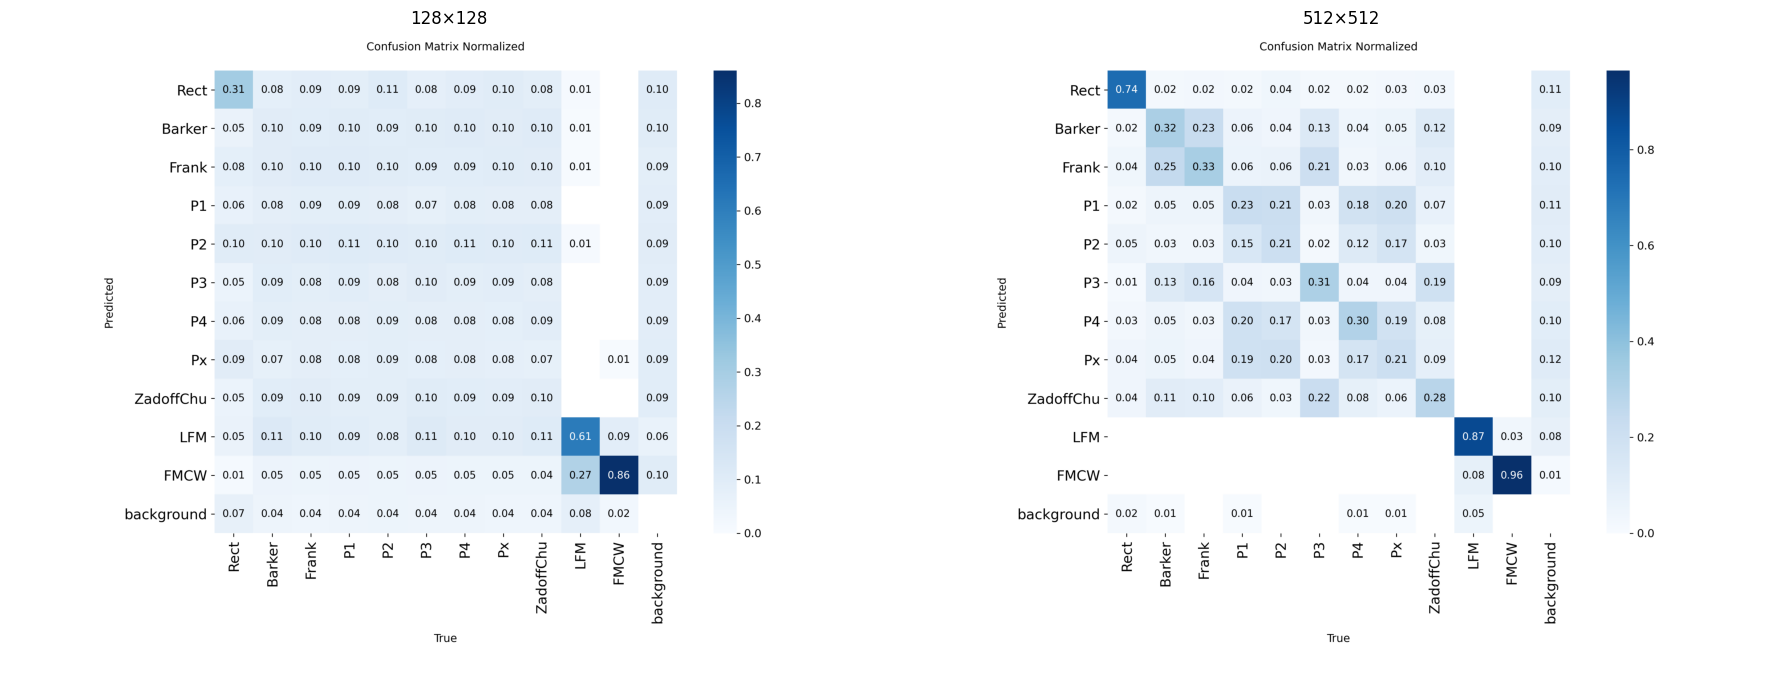

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(18, 8))
for a, S in zip(ax, [128, 512]):
    a.imshow(plt.imread(f"runs/test_{S}/confusion_matrix_normalized.png")); a.axis('off'); a.set_title(f"{S}×{S}")
plt.tight_layout()

**Вопрос:** какие классы перестают путаться при переходе к 512? Сравните с картинкой классов на лекции.

### 4.4. Скорость

Задача реального времени: один кадр — это 2 мс эфира, значит, чтобы успевать за непрерывным потоком, нужно **≥ 500 кадров/с**. Меряем честно: одно и то же железо, прогрев перед замером, вместе с предобработкой и NMS; отдельно для пакета из 1 кадра (задержка) и из 32 кадров (пропускная способность). Каждый замер повторяем 200 раз и берём **медиану** — одиночные замеры на GPU сильно «шумят».

Время из лога `val` выше сюда не подходит: там порог уверенности 0.001, рамок очень много, и постобработка идёт долго.

In [25]:
import torch
def sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()

def bench(S, batch, n_rep=200):
    files = [f"{ROOT if S == 128 else ROOT_512}/images/test/{i}.png" for i in eval_ids[:batch]]
    imgs = [np.array(Image.open(f))[..., :3] for f in files]      # чтение с диска не считаем
    for _ in range(10): models[S].predict(imgs, imgsz=S, verbose=False)   # прогрев
    times = []
    for _ in range(n_rep):
        sync(); t0 = time.perf_counter()
        models[S].predict(imgs, imgsz=S, verbose=False)
        sync(); times.append(time.perf_counter() - t0)
    return np.median(times) / batch * 1000                          # мс на кадр

def bench_energy(S, n=200):
    imgs = [load_frame('test', i, root=ROOT if S == 128 else ROOT_512)[0] for i in eval_ids[:n]]
    times = []
    for im in imgs:
        t0 = time.perf_counter(); energy_detector(to_power(im), **energy_params(S)); times.append(time.perf_counter() - t0)
    return np.median(times) * 1000

t_energy = {S: bench_energy(S) for S in [128, 512]}
speed = pd.DataFrame({
    'YOLO26s 128 (GPU)': {'мс/кадр, пакет 1': bench(128, 1), 'мс/кадр, пакет 32': bench(128, 32)},
    'YOLO26s 512 (GPU)': {'мс/кадр, пакет 1': bench(512, 1), 'мс/кадр, пакет 32': bench(512, 32)},
    'Энергетический 128 (CPU)': {'мс/кадр, пакет 1': t_energy[128], 'мс/кадр, пакет 32': t_energy[128]},
    'Энергетический 512 (CPU)': {'мс/кадр, пакет 1': t_energy[512], 'мс/кадр, пакет 32': t_energy[512]}}).T
speed['кадров/с (пакет 32)'] = 1000 / speed['мс/кадр, пакет 32']
speed['успевает за эфиром (≥500 кадров/с)?'] = np.where(speed['кадров/с (пакет 32)'] >= 500, 'Да', 'Нет')
print("Устройство:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
speed.round(2)


Устройство: NVIDIA GeForce RTX 4060 Ti


,"мс/кадр, пакет 1","мс/кадр, пакет 32",кадров/с (пакет 32),успевает за эфиром (≥500 кадров/с)?
YOLO26s 128 (GPU),6.71,0.91,1096.88,Да
YOLO26s 512 (GPU),7.75,4.72,211.66,Нет
Энергетический 128 (CPU),1.63,1.63,614.25,Да
Энергетический 512 (CPU),43.91,43.91,22.77,Нет


**Обратите внимание:**
- результат, конечно же, зависит от железа;
- на пакете из 1 кадра время почти не зависит от разрешения: его съедают накладные расходы (запуск ядер, копирование на GPU), а не вычисления. Разница 128 и 512 видна на пакете 32;
- энергетический обнаружитель считает каждый кадр отдельно на CPU, поэтому для него «пакет 1» и «пакет 32» совпадают.


## 5. Сравнение: энергетический обнаружитель против YOLO-128 и YOLO-512

Считаем **класс-независимый AP** (найден ли сигнал вообще) на одних и тех же кадрах. Каждый метод сравнивается с разметкой в своём разрешении: IoU не зависит от масштаба, поэтому числа сопоставимы.

**Это не тот же mAP, что в разделе 4.3.** Там — mAP **с учётом класса**, усреднённый по 11 классам, на всём test (20 000 кадров). Здесь — AP **без учёта класса** на 2 000 кадров. Разница между ними показывает, сколько модель теряет именно на распознавании типа сигнала.

,Энергетический 128,Энергетический 512,YOLO26s 128,YOLO26s 512
-20.0,0.006,0.012,0.533,0.813
-12.0,0.063,0.252,0.756,0.910
-4.0,0.170,0.527,0.776,0.925
4.0,0.173,0.363,0.776,0.912
12.0,0.088,0.066,0.791,0.920
20.0,0.035,0.023,0.797,0.934
все,0.078,0.151,0.735,0.900


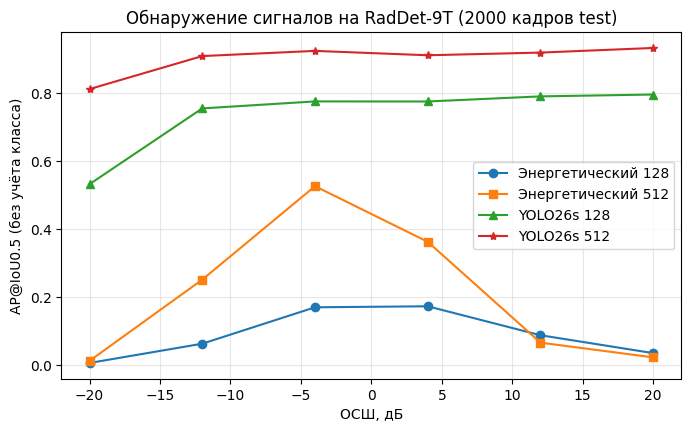

In [26]:
def yolo_preds(S):
    root = ROOT if S == 128 else ROOT_512
    out = {}
    for k in range(0, len(eval_ids), 64):
        b = eval_ids[k:k + 64]
        for i, rr in zip(b, models[S].predict([f"{root}/images/test/{i}.png" for i in b], imgsz=S, conf=0.001, iou=0.6, verbose=False)):
            out[i] = np.c_[rr.boxes.xyxy.cpu().numpy(), rr.boxes.conf.cpu().numpy()]
    return out

yolo_by_id = {128: yolo_preds(128), 512: yolo_preds(512)}

cmp = pd.DataFrame({'Энергетический 128': ap_by_snr(energy_by_id, 0.5),
                    'Энергетический 512': ap_by_snr(energy_by_id_512, 0.5, gt_by_id_512),
                    'YOLO26s 128': ap_by_snr(yolo_by_id[128], 0.5),
                    'YOLO26s 512': ap_by_snr(yolo_by_id[512], 0.5, gt_by_id_512)})
display(cmp.round(3))
snrs = [s for s in cmp.index if s != 'все']
plt.figure(figsize=(8, 4.5))
for col, mk in zip(cmp.columns, ['o-', 's-', '^-', '*-']):
    plt.plot(snrs, cmp.loc[snrs, col], mk, label=col)
plt.xlabel('ОСШ, дБ'); plt.ylabel('AP@IoU0.5 (без учёта класса)'); plt.legend(); plt.grid(alpha=.3)
plt.title('Обнаружение сигналов на RadDet-9T (2000 кадров test)');


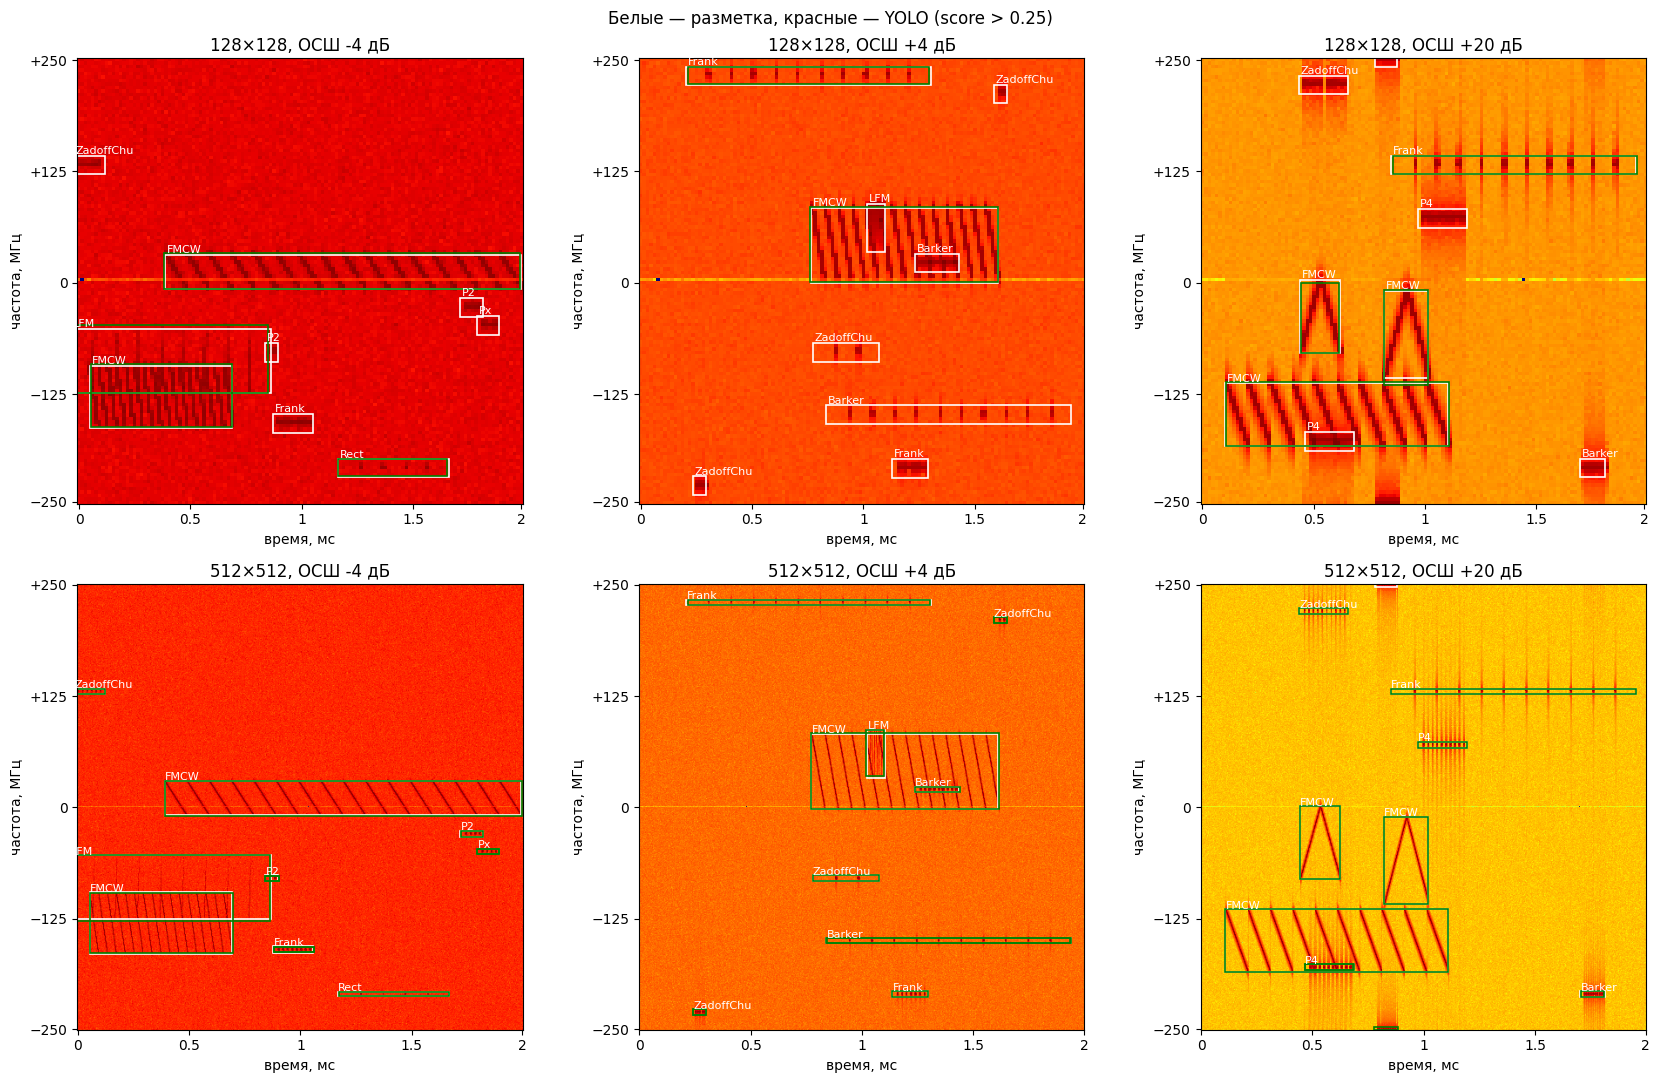

In [23]:
# Глазами: один и тот же кадр в 128 и 512 с предсказаниями
fig, axs = plt.subplots(2, 3, figsize=(17, 11))
for col, s in enumerate([-4, 4, 20]):
    i = max([j for j in eval_ids if snr_by_id[j] == s], key=lambda j: len(gt_by_id[j]))
    for row, S in enumerate([128, 512]):
        img, lab, _ = load_frame('test', i, ROOT if S == 128 else ROOT_512)
        yp = yolo_by_id[S][i]; yp = yp[yp[:, 4] > 0.25]
        show(img, lab, ax=axs[row, col], pred=yp, title=f"{S}×{S}, ОСШ {s:+d} дБ")
plt.suptitle('Белые — разметка, зелёные — YOLO (score > 0.25)'); plt.tight_layout()